# Лабораторная работа 1. Предобработка текста и статистическая языковая модель

Корпус: русскоязычные короткие сообщения (твиты) о телеком-операторах и банках с разметкой тональности (`label` ∈ {−1, 0, 1}).

In [2]:
import re
import math
import html
import random
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import stopwords
from nltk.stem.snowball import SnowballStemmer
import pymorphy3

nltk.download("stopwords", quiet=True)

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

DATA_DIR = Path(r"C:\Users\Diosa\Desktop\Master\3\texts-anaysis-26\lab1")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["font.size"] = 11
plt.rcParams["font.family"] = ["Segoe UI", "Tahoma", "DejaVu Sans"]

## 1. Загрузка данных, целевая колонка и стратифицированная выборка 80/20

Целевая текстовая колонка — `text`, в ней лежит документ, который мы анализируем и по которому строим языковую модель.

Колонка `label` — класс тональности (−1 / 0 / 1). Стратификация нужна, чтобы в обучении и тесте сохранились те же доли классов, что и в исходном корпусе: иначе оценка перплексии и выводы по шуму могли бы сместиться в сторону одного класса.

Оба parquet-файла содержат по 3000 документов, объединяем их, убираем полные дубликаты текста и заново делим 80/20 со стратификацией по `label`.

In [6]:
train_raw = pd.read_parquet(DATA_DIR / "train-00000-of-00001.parquet")
test_raw = pd.read_parquet(DATA_DIR / "test-00000-of-00001.parquet")

print("Колонки train:", list(train_raw.columns), "форма:", train_raw.shape)
print("Колонки test:", list(test_raw.columns), "форма:", test_raw.shape)
print("\nПример документов:")
display(train_raw.head(3))
print("Распределение классов в исходных файлах:")
print("train:\n", train_raw["label"].value_counts().sort_index())
print("test:\n", test_raw["label"].value_counts().sort_index())

Колонки train: ['text', 'label'] форма: (3000, 2)
Колонки test: ['text', 'label'] форма: (3000, 2)

Пример документов:


,text,label
0,Блядский пидорский билайн. извините но нет сил,-1
1,Почему МТС в Дагестане не работает? Кто знает?,-1
2,"у меня теле2 уже больше 10 лет, так что можешь...",-1


Распределение классов в исходных файлах:
train:
 label
-1    1000
 0    1000
 1    1000
Name: count, dtype: int64
test:
 label
-1    1000
 0    1000
 1    1000
Name: count, dtype: int64


In [8]:
TEXT_COL = "text"
LABEL_COL = "label"

full = pd.concat([train_raw, test_raw], ignore_index=True)
n_before = len(full)
full = full.dropna(subset=[TEXT_COL, LABEL_COL]).copy()
full[TEXT_COL] = full[TEXT_COL].astype(str)
full = full.drop_duplicates(subset=[TEXT_COL]).reset_index(drop=True)

print(f"Объединено документов: {n_before}")
print(f"После удаления пустых и дубликатов текста full: {len(full)}")
print("Классы после очистки дубликатов full:\n", full[LABEL_COL].value_counts().sort_index())

train_df, test_df = train_test_split(
    full,
    test_size=0.2,
    stratify=full[LABEL_COL],
    random_state=RANDOM_STATE,
)
train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print(f"\nИтоговая выборка: train={len(train_df)} ({len(train_df)/len(full):.0%}), "
      f"test={len(test_df)} ({len(test_df)/len(full):.0%})")
print("\nДоли классов (стратификация):")
cmp = pd.DataFrame({
    "full": full[LABEL_COL].value_counts(normalize=True).sort_index(),
    "train": train_df[LABEL_COL].value_counts(normalize=True).sort_index(),
    "test": test_df[LABEL_COL].value_counts(normalize=True).sort_index(),
})
display(cmp.round(4))

Объединено документов: 6000
После удаления пустых и дубликатов текста full: 5677
Классы после очистки дубликатов full:
 label
-1    1794
 0    1985
 1    1898
Name: count, dtype: int64

Итоговая выборка: train=4541 (80%), test=1136 (20%)

Доли классов (стратификация):


,full,train,test
label,,,
-1,0.3160,0.3160,0.3160
0,0.3497,0.3497,0.3495
1,0.3343,0.3343,0.3345


## 2. Структура данных — только обучающая выборка

Все описательные статистики считаем по train. Смотрим:
- число документов;
- среднюю длину в словах (пробельная токенизация) и в символах;
- распределение длин, нет ли выбросов;
- частоту стоп-слов,  «не», «в», «на» доминируют.

In [11]:
train_texts = train_df[TEXT_COL].tolist()
n_docs = len(train_texts)
char_lens = np.array([len(t) for t in train_texts])
word_lens = np.array([len(t.split()) for t in train_texts])

print(f"Документов в train: {n_docs}")
print(f"Средняя длина, символы: {char_lens.mean():.2f}  (медиана {np.median(char_lens):.0f}, min={char_lens.min()}, max={char_lens.max()})")
print(f"Средняя длина, слова:   {word_lens.mean():.2f}  (медиана {np.median(word_lens):.0f}, min={word_lens.min()}, max={word_lens.max()})")
print(f"Пустых/очень коротких предложений (<3 слов): {(word_lens < 3).sum()}")

Документов в train: 4541
Средняя длина, символы: 88.75  (медиана 82, min=10, max=172)
Средняя длина, слова:   11.71  (медиана 11, min=1, max=27)
Пустых/очень коротких предложений (<3 слов): 20


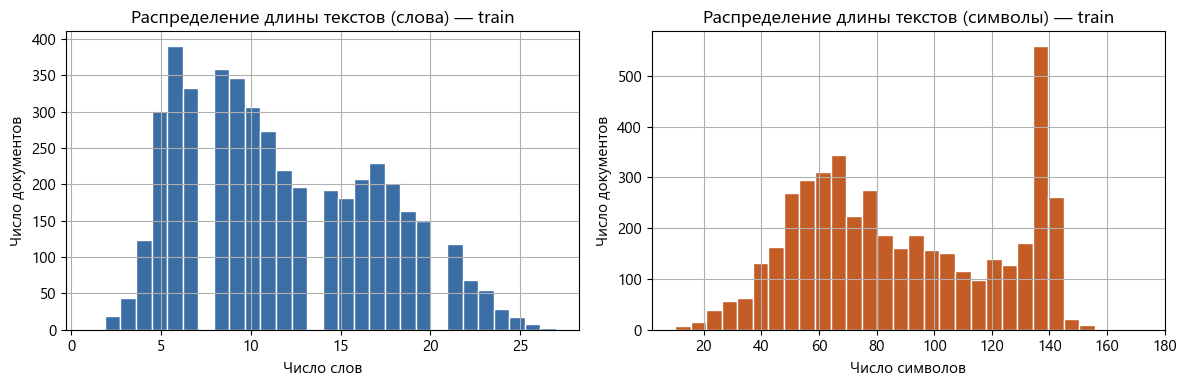

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(word_lens, bins=30, color="#3b6ea5", edgecolor="white")
axes[0].set_title("Распределение длины текстов (слова) — train")
axes[0].set_xlabel("Число слов")
axes[0].set_ylabel("Число документов")
axes[1].hist(char_lens, bins=30, color="#c45c26", edgecolor="white")
axes[1].set_title("Распределение длины текстов (символы) — train")
axes[1].set_xlabel("Число символов")
axes[1].set_ylabel("Число документов")
plt.tight_layout()
plt.show()

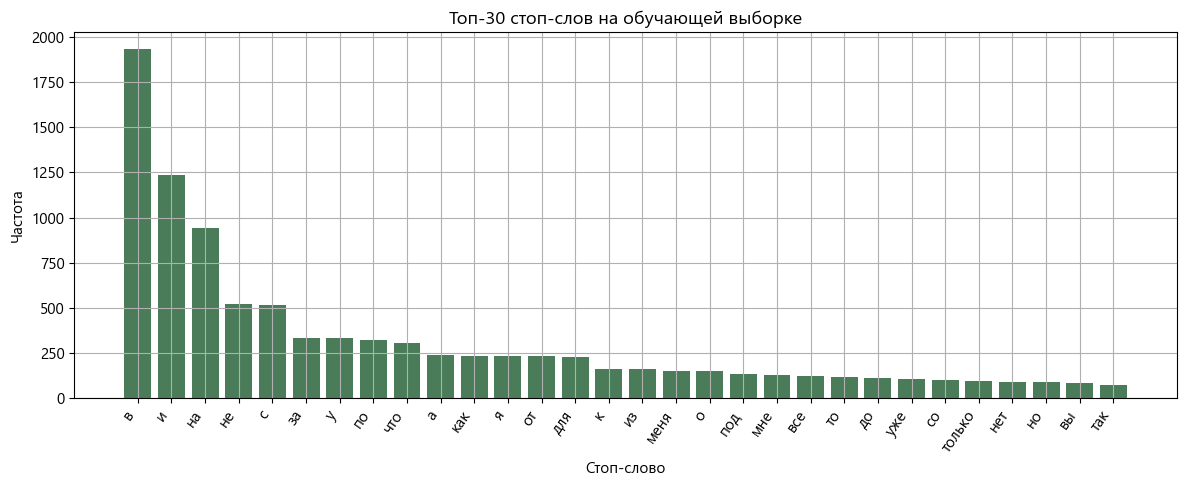

Самые частые стоп-слова: в (1933), и (1235), на (941), не (521), с (516), за (334), у (330), по (321), что (304), а (237)


In [13]:
ru_stop = set(stopwords.words("russian"))
token_re = re.compile(r"[а-яёa-z]+", re.IGNORECASE)

stop_counter = Counter()
for t in train_texts:
    for w in token_re.findall(t.lower()):
        if w in ru_stop:
            stop_counter[w] += 1

top30 = stop_counter.most_common(30)
words, freqs = zip(*top30)

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(len(words)), freqs, color="#4a7c59")
ax.set_xticks(range(len(words)))
ax.set_xticklabels(words, rotation=55, ha="right")
ax.set_title("Топ-30 стоп-слов на обучающей выборке")
ax.set_xlabel("Стоп-слово")
ax.set_ylabel("Частота")
plt.tight_layout()
plt.show()

print("Самые частые стоп-слова:", ", ".join(f"{w} ({c})" for w, c in top30[:10]))

Сообщения короткие (характерный лимит Twitter ~140–160 символов), распределение длин приближено к нормальному. Стоп-слова типичны для разговорного русского разговорного (`не`, `в`, `на`, `и`, `что`) — отрицание `не` особенно частотно, что ожидаемо для отзывов и жалоб.

## 3. Специфический шум домена


In [29]:
PATTERNS = {
    "URL (http/https/www/t.co)": re.compile(r"https?://\S+|www\.\S+|t\.co/\S+", re.I),
    "Twitter-ники @user": re.compile(r"@\w+"),
    "Хештеги #tag": re.compile(r"#\w+"),
    "Префикс репоста RT": re.compile(r"\bRT\b"),
    "HTML-сущности (&amp; и др.)": re.compile(r"&(?:amp|quot|lt|gt|nbsp);", re.I),
    "E-mail": re.compile(r"[\w.+-]+@[\w-]+\.[\w.]+", re.I),
    "Смайлики ASCII": re.compile(r"(?:[:;=8][-']*[)(/\\DPpOo]|[)(/\\D][-']*[:;=8])"),
}

joined = "\n".join(train_texts)
print(f"Документов train: {n_docs}\n")
for name, rx in PATTERNS.items():
    hits = rx.findall(joined)
    docs_with = sum(1 for t in train_texts if rx.search(t))
    print(f"{name:32s}  совпадений={len(hits):5d}  документов={docs_with:5d}  ({100*docs_with/n_docs:.1f}%)")
    if hits:
        print("   примеры:", hits[:5])

Документов train: 4541

URL (http/https/www/t.co)         совпадений= 1990  документов= 1901  (41.9%)
   примеры: ['http://t.co/l2raqLlAR7', 'http://t.co/8cKNMe5Ak0', 'http://t.co/Uc2B8W0ZvJ', 'http://t.co/ltFM6lZHYW”', 'http://t.co/owlHt0tt3S']
Twitter-ники @user                совпадений= 1728  документов= 1444  (31.8%)
   примеры: ['@Beeline_RUS', '@Beeline_RUS', '@vesti_kpss', '@reckless_zx', '@narodnaya_volya']
Хештеги #tag                      совпадений= 1318  документов=  854  (18.8%)
   примеры: ['#Яндекс', '#Yandex', '#Банк', '#МТС', '#явшоке']
Префикс репоста RT                совпадений=  712  документов=  690  (15.2%)
   примеры: ['RT', 'RT', 'RT', 'RT', 'RT']
HTML-сущности (&amp; и др.)       совпадений=  165  документов=   87  (1.9%)
   примеры: ['&amp;', '&amp;', '&amp;', '&amp;', '&amp;']
E-mail                            совпадений=   17  документов=   17  (0.4%)
   примеры: ['blogs@mts.ru', '+380685302855@sms.beeline.ua', 'pomogite@beeline.ru.Обязательно', 'pomogite@

In [26]:
print("Примеры «грязных» документов:\n")
shown = 0
for t in train_texts:
    if ("http" in t.lower() or t.startswith("RT") or "@" in t) and ("#" in t or "&amp;" in t or ":)" in t or ":(" in t):
        print("—", t)
        print()
        shown += 1
        if shown >= 6:
            break

Примеры «грязных» документов:

— Сайт хорошего тона. Специалисты оценили новый сайт крупнейшего банка России: Сбербанк представил тес... http://t.co/Uc2B8W0ZvJ #Банк

— @reckless_zx, контролировать свои расходы можно с помощью Интернет-помощника: https://t.co/oMOFjnfbvR. ^ДП #МТС

— #РИА #экономика Приставы в Улан-Удэ арестовали счета "Байкалфарма" за долг Сбербанку http://t.co/WCbIEkTpjf

— Вот такую чудную композицию из полевых цветов Вам дарит #мегафон в честь дня рождения компании @MegaFonUral http://t.co/gpWtnGYv20

— МТС ввел звонок из роуминга за счет вызываемого абонента http://t.co/ZX2jrecNHN #runews #fact #russia #ukraine

— RT @alfa_bank: @tsvetik26 Спасибо большое! И вас с наступающим! :)



## 4. Конвейер очистки на регулярных выражениях

Буквы чужого алфавита, бренды (`МТС`, `Beeline`) и введённые технические токены сохраняем. Числа для языковой модели конкретной величины обычно не несут (тариф `350` vs `400` — редкие типы), поэтому нормализуем в `[NUM]`. В конец каждого документа добавляем границы последовательности `<s>` и `</s>` — они понадобятся n-граммной модели как явные состояния Марковской цепи.

In [33]:
RE_HTML_ENTITY = re.compile(r"&(?:[a-z]+|#\d+);", re.I)
RE_URL = re.compile(r"(?:https?://|www\.)\S+|t\.co/\S+", re.I)
RE_EMAIL = re.compile(r"[\w.+-]+@[\w-]+\.[a-z]{2,}", re.I)
RE_USER = re.compile(r"@\w+")
RE_HASHTAG = re.compile(r"#(\w+)", re.I)
RE_RT = re.compile(r"\brt\b", re.I)
RE_EMO = re.compile(
    r"(?:[:;=8][-']*[)(/\\DPpOo*|]+|[)(/\\D][-']*[:;=8]|\)\)+|\(+|\]+:)"
)
RE_NUM = re.compile(r"\b\d+(?:[.,]\d+)?\b")
RE_KEEP = re.compile(r"[^0-9a-zа-яё\[\]_<>\s]+", re.I)
RE_SPACE = re.compile(r"\s+")

SPECIAL_TOKENS = {"[url]", "[user]", "[hashtag]", "[email]", "[num]", "[emo]", "[unk]", "<s>", "</s>"}


def clean_text(text: str) -> str:
    """Пошаговая очистка: типы шума заменяются токенами."""
    t = html.unescape(str(text))
    t = RE_HTML_ENTITY.sub(" ", t)
    t = RE_URL.sub(" [url] ", t)
    t = RE_EMAIL.sub(" [email] ", t)
    t = RE_USER.sub(" [user] ", t)
    t = RE_HASHTAG.sub(r" [hashtag] \1 ", t)
    t = RE_RT.sub(" ", t)
    t = RE_EMO.sub(" [emo] ", t)
    t = RE_NUM.sub(" [num] ", t)
    t = t.replace("«", " ").replace("»", " ").replace('"', " ")
    t = RE_KEEP.sub(" ", t)
    t = RE_SPACE.sub(" ", t).strip().lower()
    return t


def wrap_sequence(cleaned: str) -> str:
    return f"<s> {cleaned} </s>" if cleaned else "<s> </s>"


def tokenize(cleaned_wrapped: str) -> list[str]:
    return cleaned_wrapped.split()


demo = [
    "RT @lezykokamok: ФАС может оштрафовать «ВымпелКом» и Apple из-за LTE #news http://t.co/abc",
    "у меня теле2 уже больше 10 лет:) пишите на pomogite@beeline.ru !!!",
    "&amp;quot;Система&amp;quot; @Beeline_RUS (( это уже за гранью...",
]
print("Демонстрация правил очистки:\n")
for raw in demo:
    cl = wrap_sequence(clean_text(raw))
    print("Исходный:", raw)
    print("Очищенный:", cl)
    print()

Демонстрация правил очистки:

Исходный: RT @lezykokamok: ФАС может оштрафовать «ВымпелКом» и Apple из-за LTE #news http://t.co/abc
Очищенный: <s> [user] фас может оштрафовать вымпелком и apple из за lte [hashtag] news [url] </s>

Исходный: у меня теле2 уже больше 10 лет:) пишите на pomogite@beeline.ru !!!
Очищенный: <s> у меня теле2 уже больше [num] лет [emo] пишите на [email] </s>

Исходный: &amp;quot;Система&amp;quot; @Beeline_RUS (( это уже за гранью...
Очищенный: <s> система [user] [emo] это уже за гранью </s>



In [34]:
train_df = train_df.copy()
test_df = test_df.copy()
train_df["cleaned"] = train_df[TEXT_COL].map(lambda x: wrap_sequence(clean_text(x)))
test_df["cleaned"] = test_df[TEXT_COL].map(lambda x: wrap_sequence(clean_text(x)))
train_df["tokens"] = train_df["cleaned"].map(tokenize)
test_df["tokens"] = test_df["cleaned"].map(tokenize)

print("Случайные пары «было → стало» (train):\n")
for i in train_df.sample(5, random_state=RANDOM_STATE).index:
    print("было: ", train_df.loc[i, TEXT_COL])
    print("стало:", train_df.loc[i, "cleaned"])
    print("---")

Случайные пары «было → стало» (train):

было:  Zaletchikya «МТС-Украина» безуспешно пытается восстановить связь в Крыму
стало: <s> zaletchikya мтс украина безуспешно пытается восстановить связь в крыму </s>
---
было:  анкета на потребительский кредит втб 24 хабаровск http://t.co/HeYSqO9XOT
стало: <s> анкета на потребительский кредит втб [num] хабаровск [url] </s>
---
было:  http://t.co/XifphFemGQ Втб 24 банк взять кредит без справки о доходах
стало: <s> [url] втб [num] банк взять кредит без справки о доходах </s>
---
было:  не ловит мтс ну ахуеть
стало: <s> не ловит мтс ну ахуеть </s>
---
было:  RT @UkrProgress: #ЕC ввел секторальные экономические санкции против #России.В списке-Сбербанк, ВТБ, Газпромбанк, ВЭБ и Россельхозбанк. http…
стало: <s> [user] [hashtag] еc ввел секторальные экономические санкции против [hashtag] россии в списке сбербанк втб газпромбанк вэб и россельхозбанк http </s>
---


## 5. Сравнительная нормализация: стемминг vs лемматизация

Словарь считаем по токенам train после очистки, исключая технические маркеры границ и плейсхолдеры шума, нас интересует лексика языка.

- **Стемминг** (Snowball для русского) отрезает окончания правилами, без словаря. Быстрый, но даёт несуществующие основы (`работает` → `работа`).
- **Лемматизация** (pymorphy3) приводит к словарной форме с учётом морфологии (`работает` → `работать`). Медленнее, но читаемее и обычно лучше для последующего анализа.

Для коротких твитов с сленгом, брендами и опечатками оба метода ошибаются: стеммер ломает аббревиатуры, лемматайзер не знает `мтсик` / `билайн`.

In [37]:
stemmer = SnowballStemmer("russian")
morph = pymorphy3.MorphAnalyzer()

WORD_RE = re.compile(r"^[а-яёa-z]+", re.I)


def is_lexical(tok: str) -> bool:
    return tok not in SPECIAL_TOKENS and bool(WORD_RE.match(tok))


def lemma_of(tok: str) -> str:
    return morph.parse(tok)[0].normal_form


raw_vocab = Counter()
stem_vocab = Counter()
lemma_vocab = Counter()

examples = []
for tokens in train_df["tokens"]:
    for tok in tokens:
        if not is_lexical(tok):
            continue
        raw_vocab[tok] += 1
        st = stemmer.stem(tok)
        lm = lemma_of(tok)
        stem_vocab[st] += 1
        lemma_vocab[lm] += 1
        if len(examples) < 12 and tok != st and tok != lm:
            examples.append((tok, st, lm))

print("Размер словаря (уникальные лексические токены, train):")
print(f"  до нормализации:     {len(raw_vocab):6d}")
print(f"  после стемминга:     {len(stem_vocab):6d}   сжатие {100*(1-len(stem_vocab)/len(raw_vocab)):.1f}%")
print(f"  после лемматизации:  {len(lemma_vocab):6d}   сжатие {100*(1-len(lemma_vocab)/len(raw_vocab)):.1f}%")

print("\nПримеры (слово → стем → лемма):")
for tok, st, lm in examples:
    print(f"  {tok:20s}  {st:16s}  {lm}")

Размер словаря (уникальные лексические токены, train):
  до нормализации:      10382
  после стемминга:       6258   сжатие 39.7%
  после лемматизации:    6382   сжатие 38.5%

Примеры (слово → стем → лемма):
  будем                 буд               быть
  дошёл                 дошел             дойти
  ростелекома           ростелеком        ростелеком
  получил               получ             получить
  почте                 почт              почта
  молодцы               молодц            молодец
  товарищи              товарищ           товарищ
  ввели                 ввел              ввести
  новые                 нов               новый
  санкции               санкц             санкция
  россии                росс              россия
  соединенные           соединен          соединить


Для используемого набора данных стемминг обеспечивает чуть большее сжатие словаря, однако лемматизация даёт более качественную языковую нормализацию.

## 6. Расстояние Левенштейна (без готовых библиотек) и поиск близких слов

Расстояние Левенштейна — метрика на множестве конечных последовательностей, определяемая как минимальное число одноэлементных операций редактирования, необходимых для превращения одной последовательности в другую. В классическом случае разрешены три операции единичной стоимости: вставка одного символа, удаление одного символа и замена одного символа другим.

Каждая ячейка D[i][j] означает минимальное количество операций, чтобы превратить первые i символов a в первые j символов b. Последняя ячейка таблицы и есть расстояние Левенштейна.

Классический DP даёт матрицу `(n+1)×(m+1)`. Для оптимизации по памяти достаточно двух строк длины `min(n, m)+1`: текущей и предыдущей. Дополнительно отсекаем пары с `|len(a)−len(b)| > 2` и прерываем расчёт строки, если её минимум уже больше 2 — нам нужны только расстояния 1 и 2.

Ищем пары лексических токенов train (длина ≥ 4, частота ≥ 2), чтобы не сравнивать опечатки-гапаксы со всем словарём вслепую. Топ-10 — наиболее частотные пары с d∈{1,2}: это и опечатки, и соседние словоформы.

In [42]:
def levenshtein(a: str, b: str, max_dist: int = 2) -> int:
    """Расстояние Левенштейна, O(min(n, m)) памяти, с отсечением по max_dist."""
    if a == b:
        return 0
    n, m = len(a), len(b)
    if abs(n - m) > max_dist:
        return max_dist + 1 # если разница в длине больше max_dist, то расстояние больше max_dist
    if n > m:
        a, b = b, a
        n, m = m, n # массивы prev и curr будут иметь размер n + 1, поэтому хотим, чтобы n было минимальным
    prev = list(range(n + 1))
    for j, cb in enumerate(b, 1):
        curr = [j] + [0] * n
        row_min = j
        for i, ca in enumerate(a, 1):
            cost = 0 if ca == cb else 1

            val = prev[i - 1] + cost # стоимость замены
            ins = curr[i - 1] + 1 # стоимость вставки
            delete = prev[i] + 1 # стоимость удаления

            curr[i] = min(val, ins, delete)

            if curr[i] < row_min:
                row_min = curr[i] 
        if row_min > max_dist:
            return max_dist + 1 # если расстояние больше max_dist, то возвращаем max_dist + 1
        prev = curr 
    return prev[n]

In [44]:
cyr_re = re.compile(r"^[а-яё]{4,}$")
candidates = [(w, c) for w, c in raw_vocab.items() if cyr_re.match(w) and c >= 2]
candidates.sort(key=lambda x: x[0])
print(f"Кандидатов для сравнения: {len(candidates)}")

by_len = defaultdict(list)
for w, c in candidates:
    by_len[len(w)].append((w, c))

pairs = []
seen = set()
for L, group in by_len.items():
    neighbor_groups = []
    for d in range(0, 3):
        neighbor_groups.extend(by_len.get(L + d, [])) # добавляем соседние группы
    for i, (w1, c1) in enumerate(group): # перебираем слова в группе
        for w2, c2 in neighbor_groups: # перебираем соседние группы
            if w2 <= w1: # если слово из соседней группы меньше или равно текущему слову, то пропускаем
                continue
            key = (w1, w2)
            if key in seen:
                continue
            dist = levenshtein(w1, w2, max_dist=2)
            if dist in (1, 2):
                seen.add(key)
                pairs.append({
                    "слово_1": w1,
                    "слово_2": w2,
                    "расстояние": dist,
                    "частота_1": c1,
                    "частота_2": c2,
                    "score": c1 * c2,
                })

pairs_df = pd.DataFrame(pairs)
top10 = pairs_df.sort_values(["score", "расстояние"], ascending=[False, True]).head(10)
print(f"Найдено пар с d∈{{1,2}}: {len(pairs_df)}  (d=1: {(pairs_df['расстояние']==1).sum()}, d=2: {(pairs_df['расстояние']==2).sum()})")
print("\nТоп-10 пар (по произведению частот):")
display(top10.drop(columns=["score"]).reset_index(drop=True))


Кандидатов для сравнения: 3633
Найдено пар с d∈{1,2}: 5714  (d=1: 1635, d=2: 4079)

Топ-10 пар (по произведению частот):


,слово_1,слово_2,расстояние,частота_1,частота_2
0,сбербанк,сбербанка,1,882,210
1,банк,банка,1,376,227
2,сбербанк,сбербанке,1,882,73
3,билайн,онлайн,2,550,93
4,билайн,билайна,1,550,83
5,кредит,кредиты,1,342,95
6,россельхозбанк,россельхозбанка,1,163,178
7,мегафон,мегафона,1,266,85
8,санкции,санкций,1,311,63
9,банк,банке,1,376,50


## 7. Статистическая bigram-модель (N=2)

Для твитов средней длины ~10–12 токенов после очистки биграммы устойчивее триграмм. «Какова вероятность встретить слово w₂, если перед ним было слово w₁?»

Главная формула биграммной модели:

$$ P(w_i|w_{i-1}) = \frac{C(w_{i-1},w_i)} {C(w_{i-1})} $$

где:

C(w_{i-1}, w_i) — сколько раз встретилась биграмма;
C(w_{i-1}) — сколько раз встретилось первое слово.

Явный словарь: токены train с частотой ≥ `MIN_FREQ`, плюс служебные `<s>`, `</s>`, `[UNK]`. Всё, что реже порога или не встречалось в train, на тесте заменяется на `[UNK]`. Так неизвестные слова из теста не получают нулевую вероятность уже на уровне униграмм.

In [48]:
N = 2
MIN_FREQ = 2
UNK = "[UNK]"
BOS = "<s>"
EOS = "</s>"

token_freq = Counter(tok for tokens in train_df["tokens"] for tok in tokens) # считаем частоту каждого токена в train
vocab = {tok for tok, c in token_freq.items() if c >= MIN_FREQ} # в словарь попадут только слова с частотой ≥ 2
vocab.update({BOS, EOS, UNK})
vocab = sorted(vocab)
vocab_set = set(vocab)
tok2id = {t: i for i, t in enumerate(vocab)} # словарь токенов в индексы

print(f"N = {N} (биграммы)")
print(f"Типов в train без учёта порога: {len(token_freq)}")
print(f"Явный словарь модели (|V|): {len(vocab)}  (min_freq={MIN_FREQ} + {UNK}/{BOS}/{EOS})")
print("Фрагмент словаря:", vocab[:25], "...")


def map_unk(tokens: list[str]) -> list[str]:
    return [t if t in vocab_set else UNK for t in tokens] # заменяем неизвестные токены на [UNK]


train_seqs = [map_unk(t) for t in train_df["tokens"]]
test_seqs = [map_unk(t) for t in test_df["tokens"]]

unk_share_train = np.mean([tok == UNK for seq in train_seqs for tok in seq])
unk_share_test = np.mean([tok == UNK for seq in test_seqs for tok in seq])
print(f"Доля [UNK] среди токенов: train={unk_share_train:.3%}, test={unk_share_test:.3%}")

N = 2 (биграммы)
Типов в train без учёта порога: 10466
Явный словарь модели (|V|): 4127  (min_freq=2 + [UNK]/<s>/</s>)
Фрагмент словаря: ['1500р', '1с', '2013г', '2014г', '2g', '3d', '3g', '3г', '3гб', '4g', '4г', '5c', '5s', '5с', '<', '</s>', '<s>', '>', '[UNK]', '[email]', '[emo]', '[hashtag]', '[num]', '[url]', '[user]'] ...
Доля [UNK] среди токенов: train=9.958%, test=14.740%


In [50]:
unigram_counts = Counter()
bigram_counts = Counter()
context_totals = Counter() # счётчик для подсчёта количества вхождений каждого слова в качестве контекста (сколько раз каждое слово выступало первым элементом биграммы)

for seq in train_seqs:
    for i, tok in enumerate(seq):
        unigram_counts[tok] += 1
        if i >= 1:
            bg = (seq[i - 1], tok)
            bigram_counts[bg] += 1
            context_totals[seq[i - 1]] += 1

total_tokens = sum(unigram_counts.values())
V = len(vocab_set) # количество уникальных токенов в словаре

print(f"Униграмм: {len(unigram_counts)}, биграмм с ненулевым счётом: {len(bigram_counts)}")
print(f"Токенов (с границами): {total_tokens}")
print("Самые частые биграммы:")
for bg, c in bigram_counts.most_common(12):
    print(f"  {c:4d}  {bg[0]} → {bg[1]}")

Униграмм: 4127, биграмм с ненулевым счётом: 24125
Токенов (с границами): 63668
Самые частые биграммы:
  1448  [url] → </s>
  1299  <s> → [user]
  1154  [UNK] → [UNK]
   670  [UNK] → </s>
   292  в → [UNK]
   256  [UNK] → в
   253  <s> → [url]
   248  <s> → [UNK]
   227  [UNK] → [url]
   189  <s> → [hashtag]
   188  [user] → [user]
   175  [hashtag] → [UNK]


## 8. Сглаживание и перплексия

MLE без сглаживания:

$$P_{\mathrm{MLE}}(w_i\mid w_{i-1}) = \frac{c(w_{i-1}, w_i)}{c(w_{i-1})}$$

Если биграмма не встречалась, вероятность ровно 0. Тогда правдоподобие всего тестового корпуса равно 0, а перплексия равна $+\infty$.  
Прим. неформально перплексия — это среднее число равновероятных вариантов, между которыми модель «колеблется» на каждом шаге при выборе следующего слова или символа (токена).  

Реализуем два классических сглаживания.

**Лаплас (add-1)**- к числителю прибавляется единица («добавляем одно» виртуальное появление), а к знаменателю — общее количество возможных исходов V.:

$$P_{\mathrm{Lap}}(w_i\mid w_{i-1}) = \frac{c(w_{i-1}, w_i)+1}{c(w_{i-1})+|V|}$$

**Линейная интерполяция** (Jelinek–Mercer) - вероятность слова вычисляется как взвешенная сумма (линейная комбинация) вероятностей более высокого и более низкого порядков.:  

$$P_{\mathrm{int}}(w_i\mid w_{i-1}) = \lambda\, P_{\mathrm{MLE}}(w_i\mid w_{i-1}) + (1-\lambda)\, P_{\mathrm{uni}}(w_i)$$

с $\lambda=0.7$ и $P_{\mathrm{uni}}(w)=c(w)/N$.

Перплексия через среднее **логарифма** правдоподобия (чтобы не получить underflow):

$$\mathrm{PP} = \exp\left(-\frac{1}{M}\sum_{i=1}^{M}\log P(w_i\mid w_{i-1})\right)$$

Суммируем только предсказания токенов после `<s>` (каждый следующий токен, включая `</s>`).

In [ ]:
LAMBDA = 0.7


def log_p_mle(prev: str, tok: str) -> float:
    denom = context_totals[prev] # количество всех случаев, когда prev было первым словом биграммы.
    if denom == 0:
        return -math.inf
    num = bigram_counts[(prev, tok)] # количество случаев, когда prev и tok были первым и вторым словом биграммы.
    if num == 0:
        return -math.inf
    return math.log(num / denom)


def log_p_laplace(prev: str, tok: str) -> float:
    denom = context_totals[prev] + V
    num = bigram_counts[(prev, tok)] + 1
    return math.log(num / denom)


def log_p_interp(prev: str, tok: str) -> float:
    p_uni = unigram_counts[tok] / total_tokens # вероятность униграммы.
    denom = context_totals[prev] # количество всех случаев, когда prev было первым словом биграммы.
    p_bi = (bigram_counts[(prev, tok)] / denom) if denom else 0.0 # вероятность токена, если он является вторым словом биграммы.
    p = LAMBDA * p_bi + (1.0 - LAMBDA) * p_uni
    if p <= 0:
        return -math.inf
    return math.log(p)


def sequence_logprob(seq: list[str], log_p_fn) -> tuple[float, int, bool]:
    log_sum = 0.0
    n_pred = 0
    zero = False
    for i in range(1, len(seq)):
        lp = log_p_fn(seq[i - 1], seq[i])
        n_pred += 1
        log_sum += lp
    return log_sum, n_pred, zero


def perplexity(seqs, log_p_fn, name: str) -> dict:
    total_log = 0.0
    m = 0
    n_zero_docs = 0
    for seq in seqs:
        lp, n_pred, zero = sequence_logprob(seq, log_p_fn)
        m += n_pred
        if zero:
            n_zero_docs += 1
            total_log = -math.inf
        elif total_log != -math.inf:
            total_log += lp
    if m == 0 or total_log == -math.inf:
        pp = float("inf")
    else:
        pp = math.exp(-total_log / m)
    avg_ll = (total_log / m) if m and total_log != -math.inf else float("-inf")
    pp_s = "inf" if math.isinf(pp) else f"{pp:.2f}"
    ll_s = "-inf" if avg_ll == float("-inf") else f"{avg_ll:.4f}"
    print(f"{name:28s}  PP={pp_s:>10}  mean logP={ll_s:>10}  нулевых док-ов={n_zero_docs}/{len(seqs)}  M={m}")
    return {"name": name, "perplexity": pp, "mean_logp": avg_ll, "zero_docs": n_zero_docs, "M": m}


print("Перплексия на TEST:\n")
res_mle = perplexity(test_seqs, log_p_mle, "MLE (без сглаживания)")
res_lap = perplexity(test_seqs, log_p_laplace, "Лаплас add-1")
res_int = perplexity(test_seqs, log_p_interp, "Интерполяция λ=0.7")

print("\nДля справки — перплексия на TRAIN (завышение качества, не для сравнения методов на тесте):")
_ = perplexity(train_seqs, log_p_mle, "MLE train")
_ = perplexity(train_seqs, log_p_laplace, "Лаплас train")
_ = perplexity(train_seqs, log_p_interp, "Интерполяция train")

Перплексия на TEST:

MLE (без сглаживания)         PP=       inf  mean logP=      -inf  нулевых док-ов=0/1136  M=14814
Лаплас add-1                  PP=    488.02  mean logP=   -6.1904  нулевых док-ов=0/1136  M=14814
Интерполяция λ=0.7            PP=     80.23  mean logP=   -4.3849  нулевых док-ов=0/1136  M=14814

Для справки — перплексия на TRAIN (завышение качества, не для сравнения методов на тесте):
MLE train                     PP=     20.61  mean logP=   -3.0258  нулевых док-ов=0/4541  M=59127
Лаплас train                  PP=    471.23  mean logP=   -6.1553  нулевых док-ов=0/4541  M=59127
Интерполяция train            PP=     26.23  mean logP=   -3.2671  нулевых док-ов=0/4541  M=59127


### Вывод

На тесте почти наверняка встретятся биграммы, которых не было в train. Для MLE хотя бы одна такая биграмма обнуляет произведение $\prod P(w_i\mid w_{i-1})$ по всему корпусу, поэтому

$$\mathrm{PP}_{\mathrm{MLE}}(D_{\mathrm{test}})=+\infty.$$

Add-1 на большом $|V|$ часто пересглаживает биграммы, знаменатель $c(w)+|V|$ доминирует, и модель становится ближе к равномерной — перплексия конечная, но высокая. Интерполяция обычно реалистичнее для твитов: частотные продолжения остаются острыми, редкие получают ненулевую униграммную вероятность.

Итого, без сглаживания bigram-LM на открытом словаре не определена на тесте; со сглаживанием перплексия конечна и пригодна для сравнения моделей.

## 9. Генерация текстов марковской цепью

Состояние — предыдущий токен (порядок 1). Старт: `<s>`. На каждом шаге сэмплируем продолжение из **наблюдавшихся** биграмм с весами интерполированной модели $P_{\mathrm{int}}$; если контекст пустой — backoff на униграммы. Стоп: выпал `</s>` или достигнута `MAX_LEN`. Так цепь остаётся марковской и не вырождается в почти равномерный Лаплас по всему $V$.

In [ ]:
MAX_LEN = 25


successors = defaultdict(list)
for (a, b), c in bigram_counts.items():
    successors[a].append(b)


def sample_next(prev: str, rng: random.Random) -> str:
    """Шаг марковской цепи: P_int(w|prev) по наблюдаемым продолжениям."""
    nxts = successors.get(prev)
    if nxts:
        weights = [math.exp(log_p_interp(prev, w)) for w in nxts] # восстанавливает обычную вероятность
        return rng.choices(nxts, weights=weights, k=1)[0]
    uni_toks = [w for w in unigram_counts if w != BOS]
    uni_w = [unigram_counts[w] for w in uni_toks]
    return rng.choices(uni_toks, weights=uni_w, k=1)[0]


def generate(rng: random.Random, max_len: int = MAX_LEN) -> list[str]:
    tokens = [BOS]
    while len(tokens) - 1 < max_len:
        nxt = sample_next(tokens[-1], rng)
        tokens.append(nxt)
        if nxt == EOS:
            break
    if tokens[-1] != EOS:
        tokens.append(EOS)
    return tokens


rng = random.Random(RANDOM_STATE)
generated = [generate(rng) for _ in range(5)]

print("Пять сгенерированных последовательностей:\n")
for i, seq in enumerate(generated, 1):
    text = " ".join(seq)
    stopped = "достигнут </s>" if seq[-1] == EOS and len(seq) - 2 < MAX_LEN else "обрезано по MAX_LEN"
    print(f"{i}. [{stopped}, длина={len(seq)}]")
    print("   ", text)
    print()

Пять сгенерированных последовательностей:

1. [обрезано по MAX_LEN, длина=27]
    <s> мтс на [UNK] [UNK] до конца января [hashtag] [UNK] в [UNK] мтс на [UNK] программа [UNK] [UNK] карты прошел проверку на падение выездного турпотока на </s>

2. [достигнут </s>, длина=6]
    <s> [user] [user] [user] ru </s>

3. [обрезано по MAX_LEN, длина=27]
    <s> за услуги почему иногда с [user] попавшие под санкц [trunc] поволжский сбербанк и втб [num] году [UNK] [url] банк москвы втб [num] [num] третий день </s>

4. [достигнут </s>, длина=6]
    <s> компания мобильные операторы [UNK] </s>

5. [достигнут </s>, длина=3]
    <s> подарили </s>



### Оценка генерации

Биграммная цепь на коротких твитах даёт локально правдоподобные стыки (часто всплывают бренды `мтс`, `билайн`, `[USER]`, `[URL]`, `[HASHTAG]`), но глобальной связности нет, модель не помнит контекст, согласование рода/числа легко ломается.